## Thoughts from 2.4.2 The Base Stock Model

Since this model has a constant time step and is re-ordering after each unit, it looks like a random walk. I simulate the sales with a Poisson distribution and look at the inventory on hand over a long time period.

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

First we model the daily sales and look at each month to verify that the average sales is as expected.

In [135]:
time_unit = 30 # days
avg_sales = 10
n_months = 100

daily_sales = np.random.poisson(avg_sales/time_unit,n_months*time_unit)
monthly_total = np.sum(np.reshape(daily_sales, (n_months,time_unit)), axis=1)
print(f"Average sales per time unit: {np.mean(monthly_total)}")

Average sales per time unit: 10.22


The reorder quanities are the same as the sales, delayed by one time unit.

In [136]:
reorders = np.roll(daily_sales, time_unit)
reorders[0:time_unit] = np.zeros(time_unit)

I then simulate the stock level as a running total minus sales plus arrived reorders.

In [137]:
initial_stock = 15

stock = np.zeros(n_months*time_unit)
stock[0] = initial_stock
for day in range(len(stock)-1):
    stock[day+1] = stock[day] - daily_sales[day] + reorders[day]

Over time, we see that we never actually get back to the initial stock and there are days with negative stock - these are days where the customer orders are backordered and they have to wait to get their item.

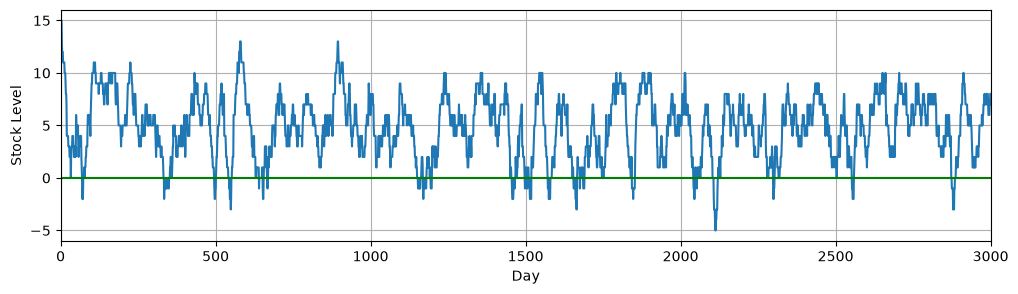

In [138]:
fig, ax = plt.subplots()
fig.set_figheight(3)
fig.set_figwidth(12)
ax.plot(stock)
ax.set_xlabel("Day")
ax.set_ylabel("Stock Level")
# ax.set_yticks(np.arange(-10,16,2))
ax.set_xlim(0,n_months*time_unit)
ax.grid()
ax.hlines(0, 0, n_months*time_unit,'g')

The stock level never gets back to the initial level.

In [139]:
max(stock[3:])

np.float64(15.0)

The number of days where we are out of stock is:

In [140]:
np.count_nonzero(stock < 0)

131

In fact, the average number of items in stock is significatly smaller than the initial stock number.

In [141]:
print(f"Average stock level {np.mean(stock)}")

Average stock level 4.807


Plotting the histogram, we see that the average is way below the total.

Text(0, 0.5, 'Days at that level')

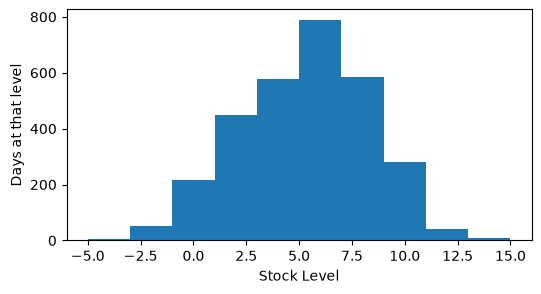

In [142]:
fig, ax = plt.subplots()
fig.set_figheight(3)
fig.set_figwidth(6)
ax.hist(stock,10)
ax.set_xlabel("Stock Level")
ax.set_ylabel("Days at that level")


Re-running these, we see that increasing the initital stock number leads to fewer backorder days at the cost of carrying more stock.

Average stock level 6.009666666666667


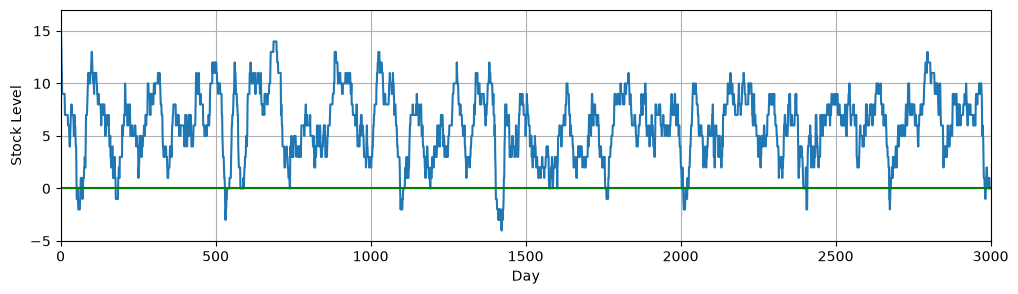

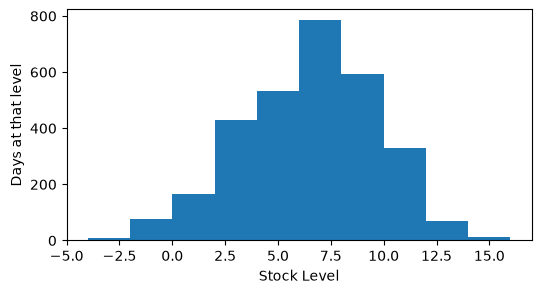

In [143]:
initial_stock = 16

daily_sales = np.random.poisson(avg_sales/time_unit,n_months*time_unit)
monthly_total = np.sum(np.reshape(daily_sales, (n_months,time_unit)), axis=1)
reorders = np.roll(daily_sales, time_unit)
reorders[0:time_unit] = np.zeros(time_unit)


stock = np.zeros(n_months*time_unit)
stock[0] = initial_stock
for day in range(len(stock)-1):
    stock[day+1] = stock[day] - daily_sales[day] + reorders[day]

fig, ax = plt.subplots()
fig.set_figheight(3)
fig.set_figwidth(12)
ax.plot(stock)
ax.set_xlabel("Day")
ax.set_ylabel("Stock Level")
# ax.set_yticks(np.arange(-10,16,2))
ax.set_xlim(0,n_months*time_unit)
ax.grid()
ax.hlines(0, 0, n_months*time_unit,'g')

fig, ax = plt.subplots()
fig.set_figheight(3)
fig.set_figwidth(6)
ax.hist(stock,10)
ax.set_xlabel("Stock Level")
ax.set_ylabel("Days at that level")
print(f"Average stock level {np.mean(stock)}")